In [23]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import pandas as pd
import pathlib as Path

DATA_DIR = Path.Path("Data")

In [24]:
with np.load(DATA_DIR / "train.npz") as data:
    print("Datasets:", data.files)
    X = data["X"]
    Y = data["y"]

    classNames = data["classes"]
    print("Class Names:", classNames)
    classes = np.unique(Y)
    print("Classes:", classes)
    print("Number of classes:", len(classes))

    bands = data["bands"]
    print("Number of bands:", len(bands))
    print("Bands:", bands)

    wavelength_nm = data["wavelength_nm"]
    print("Wavelength (nm):", wavelength_nm)
    print("Number of wavelengths:", len(wavelength_nm))
    print("Wavelengths (nm):", wavelength_nm)

    resolution_m = data["resolution_m"]
    print("Resolution (m):", resolution_m)
    print("Number of resolutions:", len(resolution_m))
    print("Resolutions (m):", resolution_m)


    

Datasets: ['X', 'y', 'classes', 'bands', 'wavelength_nm', 'resolution_m']
Class Names: ['AnnualCrop' 'Forest' 'HerbaceousVegetation' 'Highway' 'Industrial'
 'Pasture' 'PermanentCrop' 'Residential' 'River' 'SeaLake']
Classes: [0 1 2 3 4 5 6 7 8 9]
Number of classes: 10
Number of bands: 13
Bands: ['B01' 'B02' 'B03' 'B04' 'B05' 'B06' 'B07' 'B08' 'B8A' 'B09' 'B10' 'B11'
 'B12']
Wavelength (nm): [ 443  490  560  665  705  740  783  842  865  945 1375 1610 2190]
Number of wavelengths: 13
Wavelengths (nm): [ 443  490  560  665  705  740  783  842  865  945 1375 1610 2190]
Resolution (m): [60 10 10 10 20 20 20 10 20 60 60 20 20]
Number of resolutions: 13
Resolutions (m): [60 10 10 10 20 20 20 10 20 60 60 20 20]


In [25]:
for i, cls in enumerate(classes):
    print(f"Class {i}: {classNames[cls]}")

Class 0: AnnualCrop
Class 1: Forest
Class 2: HerbaceousVegetation
Class 3: Highway
Class 4: Industrial
Class 5: Pasture
Class 6: PermanentCrop
Class 7: Residential
Class 8: River
Class 9: SeaLake


In [26]:
subset = [0, 1, 7]
subsetMask = np.isin(Y, subset)
X_subset = X[subsetMask]
Y_subset = Y[subsetMask]

print("Subset Classes:", np.unique(Y_subset))
print("Subset Class Names:", classNames[np.unique(Y_subset)])

print("Subset Shape:", X_subset.shape)


Subset Classes: [0 1 7]
Subset Class Names: ['AnnualCrop' 'Forest' 'Residential']
Subset Shape: (6300, 64, 64, 13)


In [27]:
annualCropData = X_subset[Y_subset == 0]
forestData = X_subset[Y_subset == 1]
residentialData = X_subset[Y_subset == 7]

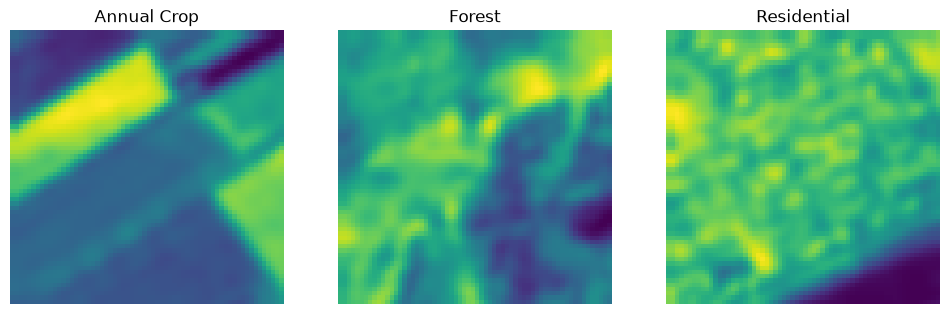

In [28]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
plt.imshow(annualCropData[69, :, :, 8])
plt.title("Annual Crop")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(forestData[69, :, :, 8])
plt.title("Forest")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(residentialData[69, :, :, 8])
plt.title("Residential")
plt.axis("off")
plt.show()

In [29]:
print(annualCropData.shape)
print(forestData.shape)
print(residentialData.shape)

assert annualCropData.shape[0] == forestData.shape[0] == residentialData.shape[0]


(2100, 64, 64, 13)
(2100, 64, 64, 13)
(2100, 64, 64, 13)


In [30]:
seed = 42
np.random.seed(seed)

randomSampleIndices = np.random.choice(len(annualCropData), size=500, replace=False)
# print("Random Sample Indices:", randomSampleIndices)

annualCropData = annualCropData[randomSampleIndices]
forestData = forestData[randomSampleIndices]
residentialData = residentialData[randomSampleIndices]

In [31]:
print("Shape of HW Dataset:")
print(annualCropData.shape)
print(forestData.shape)
print(residentialData.shape)
print("\n")

Shape of HW Dataset:
(500, 64, 64, 13)
(500, 64, 64, 13)
(500, 64, 64, 13)




In [32]:
# Spatial Averaging Images to 13D Feature Vectors
annualCropFeatures = np.mean(annualCropData, axis=(1, 2))
forestFeatures = np.mean(forestData, axis=(1, 2))
residentialFeatures = np.mean(residentialData, axis=(1, 2))

if annualCropFeatures.shape == forestFeatures.shape == residentialFeatures.shape:
    print("Shape of Feature Vectors for each class:")
    print(annualCropFeatures.shape)
    print(f"Now each image is represented by a {annualCropFeatures.shape[1]}-dimensional feature vector.")
    print("\n")


Shape of Feature Vectors for each class:
(500, 13)
Now each image is represented by a 13-dimensional feature vector.




In [33]:
trainSeed = 17
np.random.seed(trainSeed)
annucalCrodTrainIndices = np.random.choice(len(annualCropFeatures), size=int(annualCropFeatures.shape[0]*0.7), replace=False)
forestTrainIndices = np.random.choice(len(forestFeatures), size=int(forestFeatures.shape[0]*0.7), replace=False)
residentialTrainIndices = np.random.choice(len(residentialFeatures), size=int(residentialFeatures.shape[0]*0.7), replace=False)

annualCropTrain = annualCropFeatures[annucalCrodTrainIndices]
forestTrain = forestFeatures[forestTrainIndices]
residentialTrain = residentialFeatures[residentialTrainIndices]

annualCropTest = np.delete(annualCropFeatures, annucalCrodTrainIndices, axis=0)
forestTest = np.delete(forestFeatures, forestTrainIndices, axis=0)
residentialTest = np.delete(residentialFeatures, residentialTrainIndices, axis=0)


if annualCropTrain.shape == forestTrain.shape == residentialTrain.shape:
    print("Shape of Training Datasets:")
    print(annualCropTrain.shape)
    print("\n")

if annualCropTest.shape == forestTest.shape == residentialTest.shape:
    print("Shape of Test Datasets:")
    print(annualCropTest.shape)
    print("\n")



Shape of Training Datasets:
(350, 13)


Shape of Test Datasets:
(150, 13)




In [34]:
# Mean Vectors for each class
annualCropMean = np.mean(annualCropTrain, axis=0)
forestMean = np.mean(forestTrain, axis=0)
residentialMean = np.mean(residentialTrain, axis=0)

globalSMean = np.mean(np.vstack((annualCropTrain, forestTrain, residentialTrain)), axis=0)

if annualCropMean.shape == forestMean.shape == residentialMean.shape:
    print("Shape of Mean Vectors for each class:")
    print(annualCropMean.shape)
    print("\n")

Shape of Mean Vectors for each class:
(13,)




In [35]:
annualCropCentered = annualCropTrain - annualCropMean
forestCentered = forestTrain - forestMean
residentialCentered = residentialTrain - residentialMean


if annualCropCentered.shape == forestCentered.shape == residentialCentered.shape:
    print("Shape of Centered Data for each class:")
    print(annualCropCentered.shape)
    print("\n")

Shape of Centered Data for each class:
(350, 13)




In [36]:
# maximize distance between classes and minimize distance within classes
# i.e. means of each class are far apart
# i.e. data points within a class are close together

# J(W) = cost function - MAXIMISE THIS
# Maximise Sb, minimise Sw

# y = W^T x

In [37]:
annualCropS = annualCropCentered.T @ annualCropCentered
forestS = forestCentered.T @ forestCentered
residentialS = residentialCentered.T @ residentialCentered

Sw = annualCropS + forestS + residentialS

print("Shape of Within Class Scatter Matrix Sw:")
print(Sw.shape)


Shape of Within Class Scatter Matrix Sw:
(13, 13)


In [38]:
diffAnnualCrop = annualCropMean - globalSMean
diffForest = forestMean - globalSMean
diffResidential = residentialMean - globalSMean

Sb = annualCropTrain.shape[0] * np.outer(diffAnnualCrop, diffAnnualCrop) + \
     forestTrain.shape[0] * np.outer(diffForest, diffForest) + \
     residentialTrain.shape[0] * np.outer(diffResidential, diffResidential)

print("Shape of Between Class Scatter Matrix Sb:")
print(Sb.shape)


Shape of Between Class Scatter Matrix Sb:
(13, 13)


In [39]:
# Eigenvalue Decomposition

eigVal, eigVec = sp.linalg.eigh(Sb, Sw)

In [44]:
idx = np.argsort(eigVal)[::-1][:3] # small to large and then reverse it and choose the 2 largest values
WT = eigVec[:, idx]

In [45]:
# Projections
annualCropProjectionTrain = annualCropTrain @ WT
forestProjectionTrain = forestTrain @ WT
residentialProjectionTrain = residentialTrain @ WT

annualCropProjectionTest = annualCropTest @ WT
forestProjectionTest = forestTest @ WT
residentialProjectionTest = residentialTest @ WT

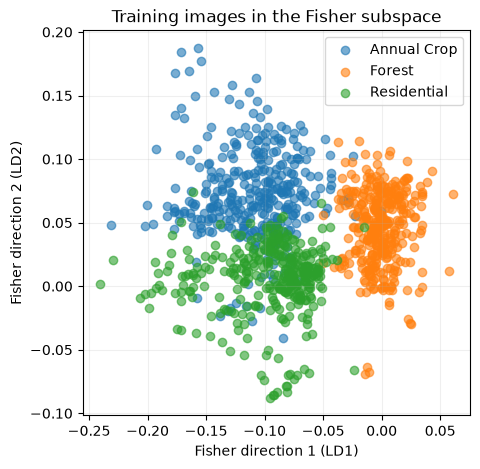

In [46]:
plt.figure(figsize=(5, 5))

plt.scatter(
    annualCropProjectionTrain[:, 0],
    annualCropProjectionTrain[:, 1],
    label="Annual Crop", alpha=0.6
)

plt.scatter(
    forestProjectionTrain[:, 0],
    forestProjectionTrain[:, 1],
    label="Forest", alpha=0.6
)

plt.scatter(
    residentialProjectionTrain[:, 0],
    residentialProjectionTrain[:, 1],
    label="Residential", alpha=0.6
)

plt.xlabel("Fisher direction 1 (LD1)")
plt.ylabel("Fisher direction 2 (LD2)")
plt.title("Training images in the Fisher subspace")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

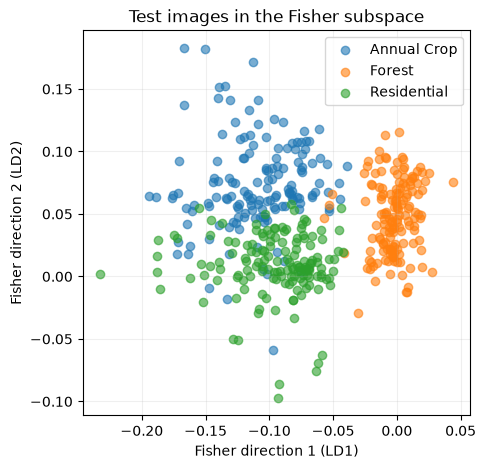

In [47]:
plt.figure(figsize=(5, 5))

plt.scatter(
    annualCropProjectionTest[:, 0],
    annualCropProjectionTest[:, 1],
    label="Annual Crop", alpha=0.6
)

plt.scatter(
    forestProjectionTest[:, 0],
    forestProjectionTest[:, 1],
    label="Forest", alpha=0.6
)

plt.scatter(
    residentialProjectionTest[:, 0],
    residentialProjectionTest[:, 1],
    label="Residential", alpha=0.6
)

plt.xlabel("Fisher direction 1 (LD1)")
plt.ylabel("Fisher direction 2 (LD2)")
plt.title("Test images in the Fisher subspace")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

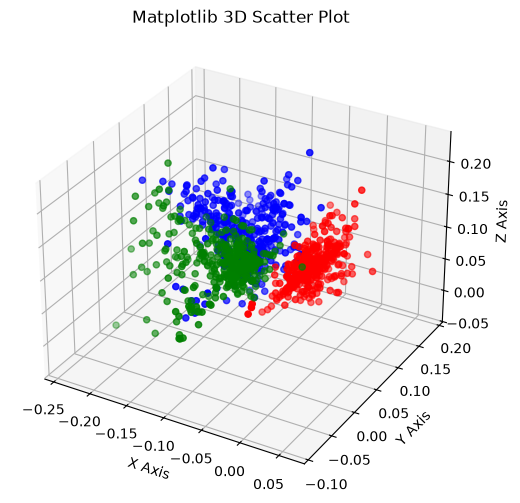

In [58]:
import matplotlib.pyplot as plt
import numpy as np

x1 = annualCropProjectionTrain[:,0]
y1 = annualCropProjectionTrain[:,1]
z1 = annualCropProjectionTrain[:,2]

x2 = forestProjectionTrain[:,0]
y2 = forestProjectionTrain[:,1]
z2 = forestProjectionTrain[:,2]

x3 = residentialProjectionTrain[:,0]
y3 = residentialProjectionTrain[:,1]
z3 = residentialProjectionTrain[:,2]


# 2. Create figure and 3D axes
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

# 3. Create the 3D scatter plot
# 'c' controls color, 'marker' sets the shape, and 's' adjusts point size
ax.scatter(x1, y1, z1, color = 'blue', marker='o', s=20)
ax.scatter(x2, y2, z2, color = 'red', marker='o', s=20)
ax.scatter(x3, y3, z3, color = 'green', marker='o', s=20)



# 4. Add labels and title
ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.set_zlabel('Z Axis')
ax.set_title('Matplotlib 3D Scatter Plot')

# 5. Display the plot
plt.show()
